In [1]:
cd ./wrkDir/s19/s19-1

/work/xiangchong.li/work/galSim-HSC/s19/s19-1


In [2]:
%pylab inline
import os
import sys
import numpy as np
import astropy.io.ascii as ascii
import pandas as pd
import scipy.stats as stats
import catutil as utilities
from scipy.interpolate import griddata

import matplotlib
import matplotlib.pyplot as plt

import logging
logging.basicConfig(filename='6-ReGaus_selBias.log',level=logging.INFO)

anaDir='./anaCat_newS19Mask_fdeltacut/'
assert os.path.isdir(anaDir)
pltDir1=os.path.join(anaDir,'plot/sanityTest/')
if not os.path.isdir(pltDir1):
    os.mkdir(pltDir1)
pltDir2=os.path.join(anaDir,'plot/sanityTest_withZ/')
if not os.path.isdir(pltDir2):
    os.mkdir(pltDir2)
inFname=os.path.join(anaDir,'allSim.h5')
assert os.path.isfile(inFname)

Populating the interactive namespace from numpy and matplotlib


98.32 percent of galaxies have HSC wide photo-z matches


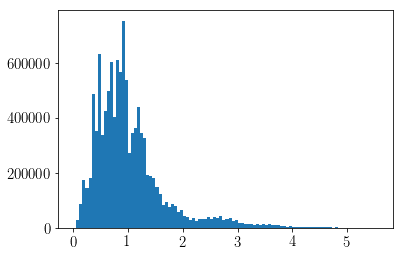

In [6]:
dataP =   pd.read_hdf(inFname,mode='r')
data=dataP.to_records()

min_snr=10
max_snr=None
max_magA10=25.5
min_res=0.3
max_mag=24.5
max_logb=-0.38
max_sigma_e=0.4
max_e=2.

wlmask2    =   utilities.galaxy_selector(catalog=data,
                min_snr=min_snr, #snr
                max_snr=max_snr,
                max_magA10=max_magA10, #magA10
                min_res=min_res, #res
                max_mag=max_mag, #mag
                max_logb=max_logb,#logb
                force_90_pair=True,
                max_e=max_e,     #absE
                max_sigma_e=max_sigma_e) #sigma_e

dataP=dataP[wlmask2&(~np.isnan(dataP['mizuki_Z']))]
data=dataP.to_records()
print('%.2f percent of galaxies have HSC wide photo-z matches' %(len(data)/np.sum(wlmask2)*100.))
a=plt.hist(data['dnn_Z'],bins=100)

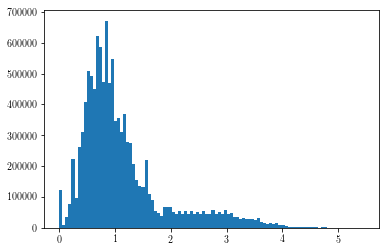

In [4]:
a=plt.hist(data['mizuki_Z'],bins=100)

$$\hat{g}_1=\frac{\sum_i w_i e_{1,i}}{2R(1+\hat{m}) \sum_i w_i}-\frac{\hat{c}_1}{1+\hat{m}}$$

$$R=H(\rm{SNR},\rm{res}) + I(z)$$
$$m=F(\rm{SNR},\rm{res}) + G(z)$$

In [4]:
def get_mc_bins(shearBinName,nbin_1d):
    outcomes=np.load(shearBinName)

    nsim   =   len(outcomes)
    psf_e1 =   np.zeros(nsim)
    psf_e2 =   np.zeros(nsim)
    weight =   np.zeros(nsim)
    g1_true=   np.zeros(nsim)
    g2_true=   np.zeros(nsim)
    g1_bins=   np.zeros((nbin_1d,nsim))
    g2_bins=   np.zeros((nbin_1d,nsim))
    sigma_g_bins=   np.zeros((nbin_1d,nsim))

    for iout,outcome in enumerate(outcomes):
        g1_true[iout]  =   outcome[0]
        g2_true[iout]  =   outcome[1]
        g1_bins[:,iout]  =   outcome[2]
        g2_bins[:,iout]  =   outcome[3]
        sigma_g_bins[:,iout]  =   outcome[4]
        psf_e1[iout]  =   outcome[5]
        psf_e2[iout]  =   outcome[6]
        weight[iout]  =   outcome[7]

    m1_bins    =   np.zeros(nbin_1d)
    a1_bins    =   np.zeros(nbin_1d)
    sigm1_bins =   np.zeros(nbin_1d)
    siga1_bins =   np.zeros(nbin_1d)

    # For each of the sliding bins in SNR/resolution.
    for j in range(nbin_1d):
        sigma_vals = sigma_g_bins[j,:]
        division_val = np.sqrt(weight)
        division_val[division_val<1.e-6] = 1.e-6
        sigma_vals /= division_val
        # remove unrealistic sim
        tmp_use = (sigma_vals < 1.e+10)
        # get multiplicative bias and additive bias
        m1_bins[j],a1_bins[j], \
        sigm1_bins[j],siga1_bins[j]= \
            utilities.get_m_c_a(g1_bins[j,tmp_use],
                                g2_bins[j,tmp_use],
                                g1_true[tmp_use],
                                g2_true[tmp_use],
                                psf_e1[tmp_use],
                                psf_e2[tmp_use],
                                sigma_vals[tmp_use],
                                separate_components=False)
    
    return m1_bins,a1_bins,sigm1_bins,siga1_bins

def makePlotSelBias(obsname,data=None,inDir=None,doPlot=True):
    nbin_1d=3
    if obsname=="mag":
        min_obs=21.5
        max_obs=24.5
        obs_bounds  =   np.linspace(min_obs,max_obs,nbin_1d+1)
        xlabel='CModel Mag'
    elif obsname=="magA10":
        min_obs=22.5
        max_obs=25.5
        obs_bounds  =   np.linspace(min_obs,max_obs,nbin_1d+1)
        xlabel='Aperture Mag'
    elif obsname=="res":
        min_obs=0.3
        max_obs=1.0
        obs_bounds  =   np.linspace(min_obs,max_obs,nbin_1d+1)
        xlabel='reGaus resolution'
    elif obsname=="snr":
        min_obs=10.
        max_obs=100.
        obs_bounds  =   np.linspace(min_obs,max_obs,nbin_1d+1)
        xlabel='CModel SNR'
    elif obsname=="COSMOS_Z":
        obs_bounds  =   np.array([0.0,0.5,1.0,1.5,2.5,4.])
        nbin_1d     =   len(obs_bounds)-1
        xlabel='COSMOS redshift'
    elif obsname=="mizuki_Z" or obsname=="dnn_Z" or obsname=="demp_Z":
        obs_bounds  =   np.array([0.0,0.5,1.0,1.5,2.5,4.])
        nbin_1d     =   len(obs_bounds)-1
        xlabel='Mizuki redshift'
    elif obsname=="mizuki_Z":
        obs_bounds  =   np.array([0.0,0.5,1.0,1.5,2.5,4.])
        nbin_1d     =   len(obs_bounds)-1
        xlabel='Mizuki redshift'
    elif obsname=="COSMOS15_Z":
        obs_bounds  =   np.array([0.0,0.5,1.0,1.5,2.5,4.])
        nbin_1d     =   len(obs_bounds)-1
        xlabel='COSMOS redshift'
    elif obsname=="COSMOS_Mag":
        min_obs=21.5
        max_obs=24.5
        obs_bounds  =   np.linspace(min_obs,max_obs,nbin_1d+1)
        xlabel='COSMOS Mag'
    elif obsname=="fwhm":
        min_obs=0.3
        max_obs=0.9
        obs_bounds  =   np.linspace(min_obs,max_obs,nbin_1d+1)
        xlabel='FWHM (arcsec)'
    obs_lowers  =   obs_bounds[:-1]
    obs_uppers  =   obs_bounds[1:]
    if data is None:
        obs_ave =   (obs_uppers+obs_lowers)/2.
    else:
        obs_ave=[]
        obs=data[obsname]
        for il,iu in zip(obs_lowers,obs_uppers):
            msk=(obs>=il)&(obs<iu)
            obs_ave.append(np.average(obs[msk]))
        obs_ave=np.array(obs_ave)
            

    shearBinName=   os.path.join(inDir,'shear_sanitytest_%s_90rot.npy' %obsname)
    m1,a1,sigm1,siga1=get_mc_bins(shearBinName,nbin_1d)

    if doPlot:
        fig = plt.figure(figsize=(12,5))
        ax = fig.add_subplot(1,2,1)
        ax.errorbar(obs_ave, m1,sigm1)
        ax.set_xlabel(xlabel,fontsize=15)
        ax.set_ylabel(r'$\delta m$',fontsize=15)
        ax.set_title('Multiplicative bias',fontsize=20)
        plt.grid()

        ax = fig.add_subplot(1,2,2)
        ax.errorbar(obs_ave, a1,siga1)
        ax.set_xlabel(xlabel,fontsize=15)
        ax.set_ylabel(r'$\delta a$',fontsize=15)
        ax.set_title('Additive bias',fontsize=20)
        plt.grid()
        plt.tight_layout()
    return obs_ave,m1*100.,sigm1*100.,a1*100.,siga1*100.

## Calibration as function of redshift

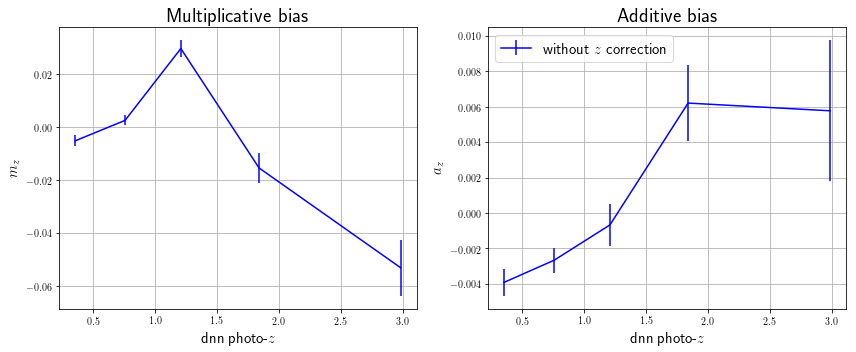

In [6]:
obsnm='dnn_Z'
xlabel=r'dnn photo-$z$'
grid1,m_res1,m_sig1,a_res1,a_sig1=makePlotSelBias(obsnm,inDir='plot/sanityTest/',data=data,doPlot=False)
out_data=list(zip(grid1,m_res1,m_sig1,a_res1, a_sig1))
mcDeltaBinTab    =   pd.DataFrame(data=out_data,columns=('z','dm','mSigma','da','aSigma'))
mcDeltaBinTab.to_csv(os.path.join(pltDir1,'dnn_z_bin_dm_da_2d.csv'))
dg=grid1[1]-grid1[0]

fig = plt.figure(figsize=(12,5))
ax = fig.add_subplot(1,2,1)
ax.errorbar(grid1-dg/80., m_res1,m_sig1,color='red',label=r'w\o $z$ correction')
ax.set_xlabel(xlabel,fontsize=15)
ax.set_ylabel(r'$m_z$',fontsize=15)
ax.set_title('Multiplicative bias',fontsize=20)
plt.grid()

ax = fig.add_subplot(1,2,2)
ax.errorbar(grid1-dg/80., a_res1,a_sig1,color='red',label=r'without $z$ correction')
ax.set_xlabel(xlabel,fontsize=15)
ax.set_ylabel(r'$a_z$',fontsize=15)
ax.set_title('Additive bias',fontsize=20)
plt.grid()
plt.legend(fontsize=15,loc='upper left')
plt.tight_layout()

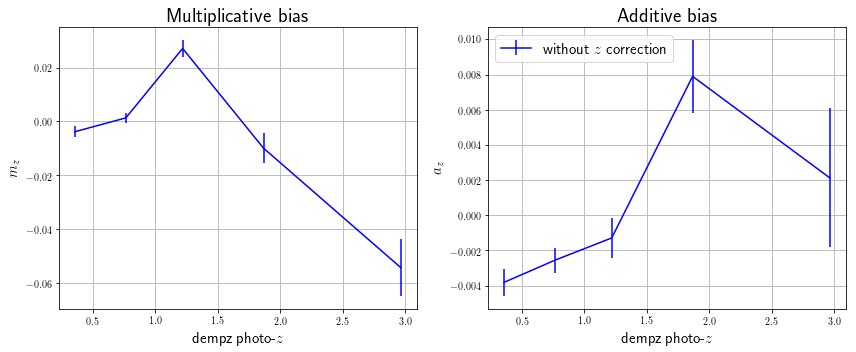

In [7]:
obsnm='demp_Z'
xlabel=r'dempz photo-$z$'

grid1,m_res1,m_sig1,a_res1,a_sig1=makePlotSelBias(obsnm,inDir='plot/sanityTest/',data=data,doPlot=False)
out_data=list(zip(grid1,m_res1,m_sig1,a_res1, a_sig1))
mcDeltaBinTab    =   pd.DataFrame(data=out_data,columns=('z','dm','mSigma','da','aSigma'))
mcDeltaBinTab.to_csv(os.path.join(pltDir1,'demp_z_bin_dm_da_2d.csv'))
dg=grid1[1]-grid1[0]

fig = plt.figure(figsize=(12,5))
ax = fig.add_subplot(1,2,1)
ax.errorbar(grid1-dg/80., m_res1,m_sig1,color='blue',label=r'w\o $z$ correction')
ax.set_xlabel(xlabel,fontsize=15)
ax.set_ylabel(r'$m_z$',fontsize=15)
ax.set_title('Multiplicative bias',fontsize=20)
plt.grid()

ax = fig.add_subplot(1,2,2)
ax.errorbar(grid1-dg/80., a_res1,a_sig1,color='blue',label=r'without $z$ correction')
ax.set_xlabel(xlabel,fontsize=15)
ax.set_ylabel(r'$a_z$',fontsize=15)
ax.set_title('Additive bias',fontsize=20)
plt.grid()
plt.legend(fontsize=15,loc='upper left')
plt.tight_layout()

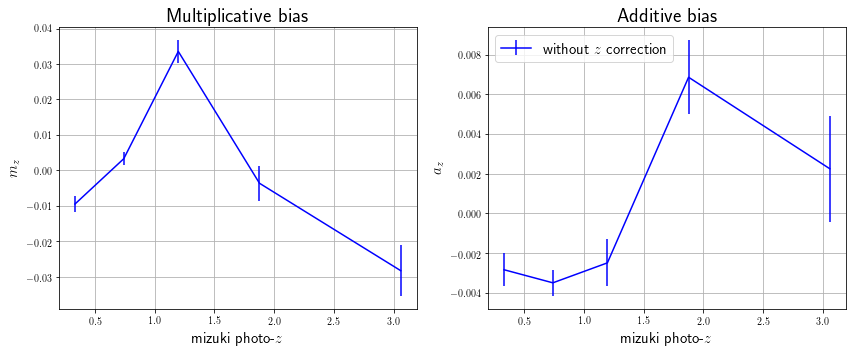

In [14]:
obsnm='mizuki_Z'
xlabel=r'mizuki photo-$z$'

grid1,m_res1,m_sig1,a_res1,a_sig1=makePlotSelBias(obsnm,inDir='plot/sanityTest/',data=data,doPlot=False)
out_data=list(zip(grid1,m_res1,m_sig1,a_res1, a_sig1))
mcDeltaBinTab    =   pd.DataFrame(data=out_data,columns=('z','dm','mSigma','da','aSigma'))
mcDeltaBinTab.to_csv(os.path.join(pltDir1,'demp_z_bin_dm_da_2d.csv'))
dg=grid1[1]-grid1[0]

fig = plt.figure(figsize=(12,5))
ax = fig.add_subplot(1,2,1)
ax.errorbar(grid1-dg/80., m_res1,m_sig1,color='blue',label=r'w\o $z$ correction')
ax.set_xlabel(xlabel,fontsize=15)
ax.set_ylabel(r'$m_z$',fontsize=15)
ax.set_title('Multiplicative bias',fontsize=20)
plt.grid()

ax = fig.add_subplot(1,2,2)
ax.errorbar(grid1-dg/80., a_res1,a_sig1,color='blue',label=r'without $z$ correction')
ax.set_xlabel(xlabel,fontsize=15)
ax.set_ylabel(r'$a_z$',fontsize=15)
ax.set_title('Additive bias',fontsize=20)
plt.grid()
plt.legend(fontsize=15,loc='upper left')
plt.tight_layout()

In [7]:
xlabel=r'photo-$z$'
grid0,m_res0,m_sig0,a_res0,a_sig0=makePlotSelBias('dnn_Z',inDir='plot/sanityTest/',data=data,doPlot=False)
grid1,m_res1,m_sig1,a_res1,a_sig1=makePlotSelBias('demp_Z',inDir='plot/sanityTest_withZ/',data=data,doPlot=False)
grid2,m_res2,m_sig2,a_res2,a_sig2=makePlotSelBias('dnn_Z',inDir='plot/sanityTest_withZ/',data=data,doPlot=False)
grid3,m_res3,m_sig3,a_res3,a_sig3=makePlotSelBias('mizuki_Z',inDir='plot/sanityTest_withZ/',data=data,doPlot=False)
dg=grid1[1]-grid1[0]

-0.05923564091311655


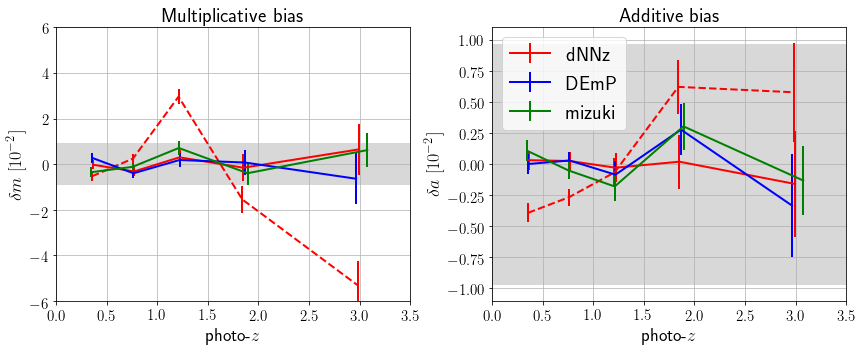

In [10]:
plt.close()
fig = plt.figure(figsize=(12,5))
fig.set_rasterized(True) 
ax = fig.add_subplot(1,2,1)
ax.errorbar(grid0-dg/80., m_res0,m_sig0,ls='--',color='red')
ax.errorbar(grid2+dg/80., m_res2,m_sig2,color='red',label=r'dNNz')
ax.errorbar(grid1-dg/80., m_res1,m_sig1,color='blue',label=r'DEmP')
ax.errorbar(grid3+dg/40., m_res3,m_sig3,color='green',label=r'mizuki')
print(np.sum(m_res3/m_sig3**2.)/np.sum(1./m_sig3**2.))
x=np.arange(0.,3.8,0.3)
y00=-0.93*np.ones(len(x))
y11=0.93*np.ones(len(x))
ax.fill_between(x, y00, y11,facecolor='grey',alpha=0.3)
ax.set_xlim(0.,3.5)
ax.set_xlabel(xlabel)
ax.set_ylim(-6,6)
ax.set_ylabel(r'$\delta m~[10^{-2}]$')
ax.set_title('Multiplicative bias',fontsize=20)
ax.set_rasterized(True)
plt.grid()

ax = fig.add_subplot(1,2,2)
ax.errorbar(grid0-dg/80., a_res0,a_sig0,ls='--',color='red')
ax.errorbar(grid2+dg/80., a_res2,a_sig2,color='red',label=r'dNNz')
ax.errorbar(grid1-dg/80., a_res1,a_sig1,color='blue',label=r'DEmP')
ax.errorbar(grid3+dg/40., a_res3,a_sig3,color='green',label=r'mizuki')
y00=-0.97*np.ones(len(x))
y11=0.97*np.ones(len(x))
ax.fill_between(x, y00, y11,facecolor='grey',alpha=0.3)
ax.set_xlim(0.,3.5)
ax.set_xlabel(xlabel)
ax.set_ylim(-1.1,1.1)
ax.set_ylabel(r'$\delta a~[10^{-2}]$')
ax.set_title('Additive bias',fontsize=20)
ax.set_rasterized(True)
plt.grid()
plt.legend(loc='upper left')
plt.tight_layout()
plt.savefig(os.path.join(pltDir2,'calibration_residual_redshfits.eps' ),rasterized=True,dpi=100)
plt.savefig(os.path.join(pltDir2,'calibration_residual_redshfits.png' ))

In [23]:
xlabel=r'photo-$z$'
grid1,m_res1,m_sig1,a_res1,a_sig1=makePlotSelBias('demp_Z',inDir='plot/sanityTest/',data=data,doPlot=False)
grid2,m_res2,m_sig2,a_res2,a_sig2=makePlotSelBias('dnn_Z',inDir='plot/sanityTest/',data=data,doPlot=False)
grid3,m_res3,m_sig3,a_res3,a_sig3=makePlotSelBias('mizuki_Z',inDir='plot/sanityTest/',data=data,doPlot=False)
dg=grid1[1]-grid1[0]

0.0026135565340297882


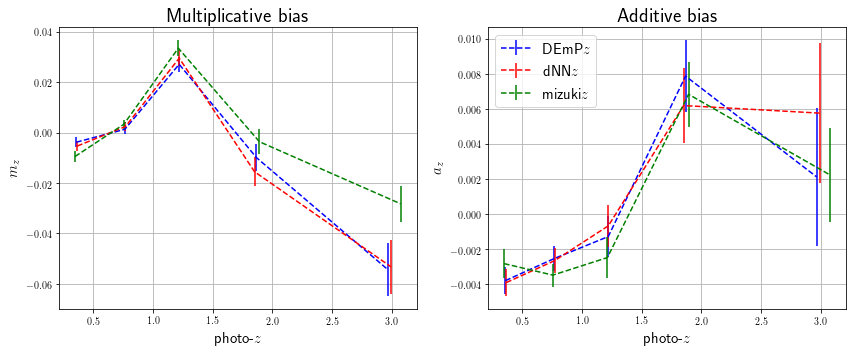

In [25]:
fig = plt.figure(figsize=(12,5))
ax = fig.add_subplot(1,2,1)
ax.errorbar(grid1-dg/80., m_res1,m_sig1,color='blue',ls='--',label=r'DEmP$z$')
ax.errorbar(grid2+dg/80., m_res2,m_sig2,color='red',ls='--',label=r'dNN$z$')
ax.errorbar(grid3+dg/40., m_res3,m_sig3,color='green',ls='--',label=r'mizuki$z$')
ax.set_xlabel(xlabel,fontsize=15)
ax.set_ylabel(r'$m_z$',fontsize=15)
ax.set_title('Multiplicative bias',fontsize=20)
plt.grid()

ax = fig.add_subplot(1,2,2)
ax.errorbar(grid1-dg/80., a_res1,a_sig1,color='blue',ls='--',label=r'DEmP$z$')
ax.errorbar(grid2+dg/80., a_res2,a_sig2,color='red',ls='--',label=r'dNN$z$')
ax.errorbar(grid3+dg/40., a_res3,a_sig3,color='green',ls='--',label=r'mizuki$z$')
ax.set_xlabel(xlabel,fontsize=15)
ax.set_ylabel(r'$a_z$',fontsize=15)
ax.set_title('Additive bias',fontsize=20)
plt.grid()
plt.legend(fontsize=15,loc='upper left')
plt.tight_layout()
plt.savefig(os.path.join(pltDir2,'calibration_residual_redshfits.eps' ))
plt.savefig(os.path.join(pltDir2,'calibration_residual_redshfits.png' ))

# Modelled Properties

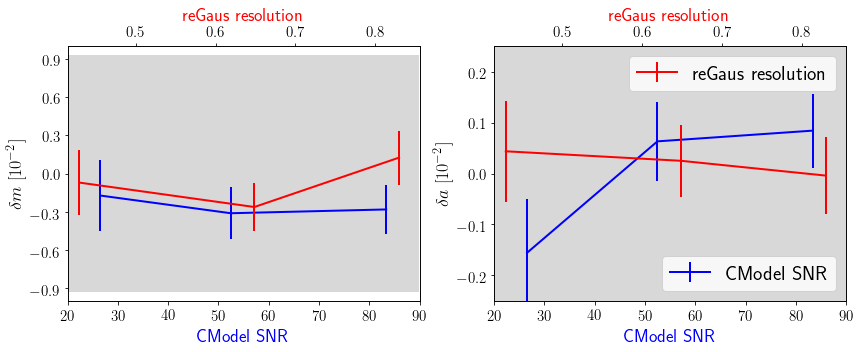

In [19]:
obsnm1='snr'
label1='CModel SNR'
grid1,m_res1,m_sig1,a_res1,a_sig1=makePlotSelBias(obsnm1,inDir='plot/sanityTest_withZ/',data=data,doPlot=False)
obsnm2='res'
label2='reGaus resolution'
grid2,m_res2,m_sig2,a_res2,a_sig2=makePlotSelBias(obsnm2,inDir='plot/sanityTest_withZ/',data=data,doPlot=False)

dg=grid1[1]-grid1[0]

plt.close()
fig = plt.figure(figsize=(12,5))
fig.set_rasterized(True) 

ax1 = fig.add_subplot(1,2,1)
ax1.errorbar(grid1, m_res1,m_sig1,color='blue',label=label1)
x=np.arange(20.,90,0.3)
y00=-0.93*np.ones(len(x))
y11=0.93*np.ones(len(x))
ax1.fill_between(x, y00, y11,facecolor='grey',alpha=0.3)
ax1.set_xlim(20,90)
ax1.set_xlabel(label1,color='blue')
ax1.set_ylabel(r'$\delta m~[10^{-2}]$')
ax1.set_rasterized(True)
ax1.set_yticks((-.9,-0.6,-0.3,0.,0.3,0.6,0.9))
ax2 = ax1.twiny()
ax2.errorbar(grid2, m_res2,m_sig2,color='red',label=label2)
ax2.set_xlabel(label2,color='red')
left, right = ax2.get_xlim()
dd=(right-left)/80.
ax2.set_xlim(left+dd,right+dd)
ax2.set_ylim(-1.,1.)
ax2.set_rasterized(True)
#plt.grid(True,which='both')

ax1 = fig.add_subplot(1,2,2)
ax1.errorbar(grid1, a_res1,a_sig1,color='blue',label=label1)
y00=-0.97*np.ones(len(x))
y11=0.97*np.ones(len(x))
ax1.fill_between(x, y00, y11,facecolor='grey',alpha=0.3)
ax1.set_xlabel(label1,color='blue')
ax1.set_ylabel(r'$\delta a~[10^{-2}]$')
ax1.legend(loc='lower right')
ax1.set_xlim(20,90)
ax1.set_rasterized(True)
ax2 = ax1.twiny()
ax2.errorbar(grid2, a_res2,a_sig2,color='red',label=label2)
ax2.set_xlabel(label2,color='red')
ax2.legend(loc='upper right')
left, right = ax2.get_xlim()
dd=(right-left)/80.
ax2.set_xlim(left+dd,right+dd)
ax2.set_ylim(-0.25,0.25)
ax2.set_rasterized(True)
#plt.grid(True,which='both')

plt.tight_layout()
plt.savefig(os.path.join(pltDir2,'calibration_residual_modeled.eps' ),rasterized=True,dpi=100)
plt.savefig(os.path.join(pltDir2,'calibration_residual_modeled.png' ))

## Marginalized Properties

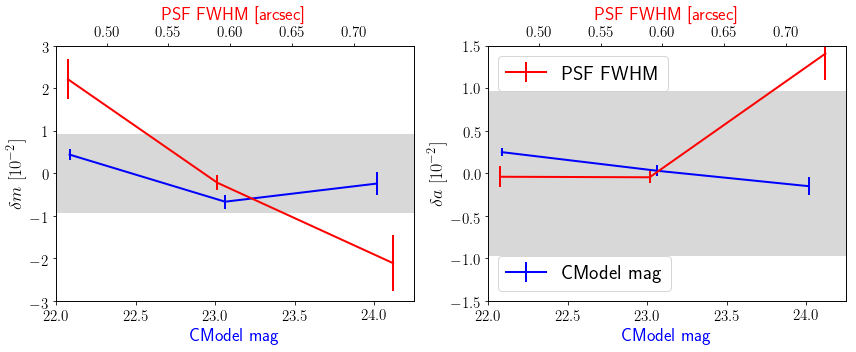

In [21]:
obsnm1='mag'
label1='CModel mag'
grid1,m_res1,m_sig1,a_res1,a_sig1=makePlotSelBias(obsnm1,inDir='plot/sanityTest_withZ/',data=data,doPlot=False)
obsnm2='fwhm'
label2='PSF FWHM [arcsec]'
grid2,m_res2,m_sig2,a_res2,a_sig2=makePlotSelBias(obsnm2,inDir='plot/sanityTest_withZ/',data=data,doPlot=False)

dg=grid1[1]-grid1[0]

fig = plt.figure(figsize=(12,5))
fig.set_rasterized(True) 

ax1 = fig.add_subplot(1,2,1)
ax1.errorbar(grid1, m_res1,m_sig1,color='blue',label=label1)
ax1.set_xlabel(label1,color='blue')
ax1.set_ylabel(r'$\delta m~[10^{-2}]$')
x=np.arange(22.,24.3,0.05)
y00=-0.93*np.ones(len(x))
y11=0.93*np.ones(len(x))
ax1.fill_between(x, y00, y11,facecolor='grey',alpha=0.3)
ax1.set_xlim(22,24.25)
ax1.set_rasterized(True)
ax2 = ax1.twiny()
ax2.errorbar(grid2, m_res2,m_sig2,color='red',label=label2.split(' [')[0])
ax2.set_xlabel(label2,color='red')
left, right = ax2.get_xlim()
dd=(right-left)/80.
ax2.set_xlim(left+dd,right+dd)
ax2.set_ylim(-3.,3.)
ax2.set_rasterized(True)
#plt.grid()

ax1 = fig.add_subplot(1,2,2)
ax1.errorbar(grid1, a_res1,a_sig1,color='blue',label=label1)
ax1.set_xlabel(label1,color='blue')
ax1.set_ylabel(r'$\delta a~[10^{-2}]$')
ax1.legend(loc='lower left')
y00=-0.97*np.ones(len(x))
y11=0.97*np.ones(len(x))
ax1.fill_between(x, y00, y11,facecolor='grey',alpha=0.3)
ax1.set_xlim(22,24.25)
ax1.set_rasterized(True)
ax2 = ax1.twiny()
ax2.errorbar(grid2, a_res2,a_sig2,color='red',label=label2.split(' [')[0])
ax2.set_xlabel(label2,color='red')
left, right = ax2.get_xlim()
dd=(right-left)/80.
ax2.set_xlim(left+dd,right+dd)
ax2.legend(loc='upper left')
ax2.set_ylim(-1.5,1.5)
ax2.set_rasterized(True)
#plt.grid()

plt.tight_layout()
plt.savefig(os.path.join(pltDir2,'calibration_residual_marginalized.eps'),rasterized=True,dpi=100)
plt.savefig(os.path.join(pltDir2,'calibration_residual_marginalized.png'))

In [7]:
indexS=  dataP.index.levels[1]
indexList= ascii.read('info_newS19Mask_fd001_sim.csv')['num']
mask=np.in1d(indexList,indexS)
indexList=indexList[mask]

outData=[]
for index in indexList:
    catalog =   dataP.xs(index,level='isim').to_records(index=False)
    reweight     =   catalog['weight'][0]
    if len(catalog)<50 or reweight<1.e-6:
        continue
    # Force the same weight and Response
    e_rms = utilities.get_erms_model(catalog)
    shape_weights = utilities.get_weight_model(catalog)*catalog['weight']
    
    # True shear
    g1_true, g2_true= utilities.get_true_shear(catalog[0])
    # PSF shapes
    psf_e1, psf_e2  =   utilities.get_psf_ellip(catalog[0])
    # Shear Estimation
    e1,e2   =   utilities.get_gal_ellip(catalog)
    shear_num_1 = np.sum(shape_weights * e1)
    shear_num_2 = np.sum(shape_weights * e2)
    sum_weight = np.sum(shape_weights)
    # Calibration
    model_m = utilities.get_m_model(catalog,weight_bias=True,photo_z_dep=True)

    model_c1,model_c2 = utilities.get_c_model(catalog,weight_bias=True,photo_z_dep=True)
    bias_num = np.sum(shape_weights*model_m)
    add_num_1 = np.sum(shape_weights*model_c1)
    add_num_2 = np.sum(shape_weights*model_c2)
    bias = bias_num / sum_weight
    resp_num = np.sum(shape_weights * e_rms**2)
    responsivity = 1.0 - resp_num/sum_weight

    g1 = shear_num_1 / (2.0*responsivity*sum_weight*(1.0+bias)) \
        - add_num_1/((1.0+bias)*sum_weight)
    g2 = shear_num_2 / (2.0*responsivity*sum_weight*(1.0+bias)) \
        - add_num_2/((1.0+bias)*sum_weight)
    sigma= 0.25/np.sqrt(len(catalog))
    
    oDat    =   (g1_true,g2_true,g1,g2,sigma,psf_e1,psf_e2,reweight)
    outData.append(oDat)
    
odf=pd.DataFrame(outData,columns=('g1_true','g2_true','g1','g2','sigma','psf_e1','psf_e2','reweight')).to_records()
division_val = np.sqrt(odf['reweight'])
division_val[division_val<1.e-6] = 1.e-6
odf['sigma'] /= division_val
# remove unrealistic sim
odf=odf[(odf['sigma'] < 1.e+10)]
# get multiplicative bias and additive bias
m1,a1,sigm1,siga1= utilities.get_m_c_a(
    odf['g1'],odf['g2'],
    odf['g1_true'],odf['g2_true'],
    odf['psf_e1'],odf['psf_e2'],
    odf['sigma'],separate_components=False)
print('m = %.4f +/- %.4f' % (m1, sigm1))
print('a = %.4f +/- %.4f' % (a1, siga1))

m = -0.0006 +/- 0.0016
a = 0.0000 +/- 0.0006


In [5]:
indexS=  dataP.index.levels[1]
indexList= ascii.read('info_newS19Mask_fd001_sim.csv')['num']
mask=np.in1d(indexList,indexS)
indexList=indexList[mask]

outData=[]
for index in indexList:
    catalog =   dataP.xs(index,level='isim').to_records(index=False)
    reweight     =   catalog['weight'][0]
    if len(catalog)<50 or reweight<1.e-6:
        continue
    # Force the same weight and Response
    e_rms = utilities.get_erms_model(catalog)
    shape_weights = utilities.get_weight_model(catalog)*catalog['weight']
    
    # True shear
    g1_true, g2_true= utilities.get_true_shear(catalog[0])
    # PSF shapes
    psf_e1, psf_e2  =   utilities.get_psf_ellip(catalog[0])
    # Shear Estimation
    e1,e2   =   utilities.get_gal_ellip(catalog)
    shear_num_1 = np.sum(shape_weights * e1)
    shear_num_2 = np.sum(shape_weights * e2)
    sum_weight = np.sum(shape_weights)
    # Calibration
    model_m = utilities.get_m_model(catalog,weight_bias=True,photo_z_dep=False)

    model_c1,model_c2 = utilities.get_c_model(catalog,weight_bias=True,photo_z_dep=False)
    bias_num = np.sum(shape_weights*model_m)
    add_num_1 = np.sum(shape_weights*model_c1)
    add_num_2 = np.sum(shape_weights*model_c2)
    bias = bias_num / sum_weight
    resp_num = np.sum(shape_weights * e_rms**2)
    responsivity = 1.0 - resp_num/sum_weight

    g1 = shear_num_1 / (2.0*responsivity*sum_weight*(1.0+bias)) \
        - add_num_1/((1.0+bias)*sum_weight)
    g2 = shear_num_2 / (2.0*responsivity*sum_weight*(1.0+bias)) \
        - add_num_2/((1.0+bias)*sum_weight)
    sigma= 0.25/np.sqrt(len(catalog))
    
    oDat    =   (g1_true,g2_true,g1,g2,sigma,psf_e1,psf_e2,reweight)
    outData.append(oDat)
    
odf=pd.DataFrame(outData,columns=('g1_true','g2_true','g1','g2','sigma','psf_e1','psf_e2','reweight')).to_records()
division_val = np.sqrt(odf['reweight'])
division_val[division_val<1.e-6] = 1.e-6
odf['sigma'] /= division_val
# remove unrealistic sim
odf=odf[(odf['sigma'] < 1.e+10)]
# get multiplicative bias and additive bias
m1,a1,sigm1,siga1= utilities.get_m_c_a(
    odf['g1'],odf['g2'],
    odf['g1_true'],odf['g2_true'],
    odf['psf_e1'],odf['psf_e2'],
    odf['sigma'],separate_components=False)
print('m = %.4f +/- %.4f' % (m1, sigm1))
print('a = %.4f +/- %.4f' % (a1, siga1))

m = 0.0035 +/- 0.0016
a = -0.0014 +/- 0.0006


In [8]:
from astropy.table import Table
indexS=  dataP.index.levels[1]
indexList= ascii.read('info_newS19Mask_fd001_sim.csv')['num']
mask=np.in1d(indexList,indexS)
indexList=indexList[mask]

outData=[]
for index in indexList:
    catalog =   Table.from_pandas(dataP.xs(index,level='isim'))
    utilities.update_reGaus_calibration(catalog)
    reweight     =   catalog['weight'][0]
    if len(catalog)<50 or reweight<1.e-6:
        continue
    # Force the same weight and Response
    e_rms =  catalog['i_hsmshaperegauss_derived_rms_e']
    shape_weights = catalog['i_hsmshaperegauss_derived_weight']*catalog['weight']
    
    # True shear
    g1_true, g2_true= utilities.get_true_shear(catalog[0])
    # PSF shapes
    psf_e1, psf_e2  =   utilities.get_psf_ellip(catalog[0])
    # Shear Estimation
    e1,e2   =   utilities.get_gal_ellip(catalog)
    shear_num_1 = np.sum(shape_weights * e1)
    shear_num_2 = np.sum(shape_weights * e2)
    sum_weight = np.sum(shape_weights)
    # Calibration
    model_m =  catalog['i_hsmshaperegauss_derived_shear_bias_m']
    model_c1=  catalog['i_hsmshaperegauss_derived_shear_bias_c1']
    model_c2 = catalog['i_hsmshaperegauss_derived_shear_bias_c2']
    bias_num = np.sum(shape_weights*model_m)
    add_num_1 = np.sum(shape_weights*model_c1)
    add_num_2 = np.sum(shape_weights*model_c2)
    bias = bias_num / sum_weight
    resp_num = np.sum(shape_weights * e_rms**2)
    responsivity = 1.0 - resp_num/sum_weight

    g1 = shear_num_1 / (2.0*responsivity*sum_weight*(1.0+bias)) \
        - add_num_1/((1.0+bias)*sum_weight)
    g2 = shear_num_2 / (2.0*responsivity*sum_weight*(1.0+bias)) \
        - add_num_2/((1.0+bias)*sum_weight)
    sigma= 0.25/np.sqrt(len(catalog))
    
    oDat    =   (g1_true,g2_true,g1,g2,sigma,psf_e1,psf_e2,reweight)
    outData.append(oDat)
    
odf=pd.DataFrame(outData,columns=('g1_true','g2_true','g1','g2','sigma','psf_e1','psf_e2','reweight')).to_records()
division_val = np.sqrt(odf['reweight'])
division_val[division_val<1.e-6] = 1.e-6
odf['sigma'] /= division_val
# remove unrealistic sim
odf=odf[(odf['sigma'] < 1.e+10)]
# get multiplicative bias and additive bias
m1,a1,sigm1,siga1= utilities.get_m_c_a(
    odf['g1'],odf['g2'],
    odf['g1_true'],odf['g2_true'],
    odf['psf_e1'],odf['psf_e2'],
    odf['sigma'],separate_components=False)
print('m = %.4f +/- %.4f' % (m1, sigm1))
print('a = %.4f +/- %.4f' % (a1, siga1))

m = -0.0006 +/- 0.0016
a = 0.0000 +/- 0.0006
